# T03 · Régularisation, normalisation, optimisation — DL/RL appliqués à la cybersécurité

**Objectifs du cours :**
- Contrôler la capacité d'un réseau (pénalités L1/L2, dropout, early stopping)
- Comprendre BatchNorm / LayerNorm au niveau des formules (moyennes / variances)
- Maîtriser SGD, momentum, RMSProp et Adam — premiers pas calculés à la main

**Pourquoi c'est fondamental en cyber :**

| Besoin cyber | Outil |
|---|---|
| Très peu d'exemples d'attaques → sur-apprentissage | L1/L2, dropout, early stopping |
| Des centaines de features de flux, beaucoup d'irrelevantes | pénalité **L1** (sélection) |
| Réseaux profonds instables (IDS, détection de malware) | BatchNorm / LayerNorm |
| Plateaux de loss, convergence lente sur gros volumes de logs | momentum, RMSProp, Adam |
| Régler un détecteur en production sans fuite de test | grille d'hyperparamètres sur **validation** |

**Prérequis :** T01 (backpropagation), T02 (vanishing gradients, overfitting).

> 💡 *Conseil étude* : exécuter chaque cellule, puis **casser les valeurs**
> (λ, p du dropout, learning rates) pour voir la courbe de validation changer.
> Un concept de régularisation qu'on a tordu une fois vaut dix pages de théorie.


## 📌 Bloc 0 — Environnement & imports

Installez le stack si besoin (déjà pré-installé sur Colab). Chaque notebook
contient des sorties pré-calculées : vous pouvez les relire sans rien exécuter,
ou « Run All » pour reproduire.

In [1]:
!pip install -q numpy scipy pandas matplotlib scikit-learn
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

np.set_printoptions(precision=3, suppress=True, linewidth=100)
print("numpy", np.__version__)

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

numpy 2.5.4


## 1 · Régularisation L1 / L2

### Ce qu'on apprend
On ajoute une **pénalité sur les poids** à la perte :

```
J(w) = Loss(w) + λ · Ω(w)
Ω_L2(w) = Σ wᵢ²        (ridge / weight decay)   → poids petits et denses
Ω_L1(w) = Σ |wᵢ|       (lasso)                  → poids **zéro** (sparsité)
```

- **L2** : le gradient de la pénalité est `2λwᵢ`, proportionnel au poids →
  les gros poids sont réduits, les petits survivent. Cas orthonormal :
  `w(λ) = w_OLS / (1 + λ)` — le **facteur de shrinkage** est mesurable.
- **L1** : le gradient est `λ·sign(wᵢ)`, constant → les petits poids atteignent
  zéro en un pas (opérateur de *soft-thresholding* : `sign(y)·max(|y|−λ, 0)`).
- En cyber : les 300 features d'un flux (durées, ratios, entropies…) sont
  surtout du bruit ; L1 sélectionne les vrais signaux d'attaque.

### Piège classique
Régulariser **l'intercept** aussi : il doit rester libre. Et toujours
**standardiser** les features avant — sinon λ écrase les features à grande
échelle et épargne celles à petite échelle.

In [2]:
def make_cyber_data(n=400, p=12, seed=7):
    """Synthetic port-scan detector data: 4 informative features, 8 pure noise."""
    rng = np.random.default_rng(seed)
    X = rng.normal(0.0, 1.0, (n, p))
    w_true = np.zeros(p)
    w_true[:4] = [1.8, -1.5, 1.2, -0.9]
    logits = X @ w_true + rng.normal(0.0, 0.5, n)
    y = (logits > 0).astype(int)
    return X, y, w_true


def ridge_closed_form(X, y, lam):
    """Argmin (1/n)||Xw - y||^2 + lam*||w||^2  =  (XtX/n + lam*I)^-1 XtY/n."""
    n = X.shape[0]
    return np.linalg.solve(X.T @ X / n + lam * np.eye(X.shape[1]), X.T @ y / n)


X_c, y_c, w_true = make_cyber_data()
Xtr, Xte, ytr, yte = train_test_split(X_c, y_c, test_size=0.4, random_state=0)
ytr_f = ytr.astype(float)

w0 = ridge_closed_form(Xtr, ytr_f, lam=0.0)
print("Poids sans regularisation :", w0)
print(f"||w(lambda=0)||2 = {np.linalg.norm(w0):.4f}")
for lam in [0.01, 0.1, 1.0, 10.0]:
    wl = ridge_closed_form(Xtr, ytr_f, lam=lam)
    print(f"lambda={lam:>5} : ||w||2 = {np.linalg.norm(wl):.4f}"
          f"   ratio = {np.linalg.norm(wl) / np.linalg.norm(w0):.4f}")

Poids sans regularisation : [ 0.236 -0.234  0.246 -0.188 -0.099 -0.011  0.005  0.003 -0.032 -0.049  0.053  0.001]
||w(lambda=0)||2 = 0.4715
lambda= 0.01 : ||w||2 = 0.4665   ratio = 0.9894
lambda=  0.1 : ||w||2 = 0.4260   ratio = 0.9035
lambda=  1.0 : ||w||2 = 0.2317   ratio = 0.4914
lambda= 10.0 : ||w||2 = 0.0425   ratio = 0.0902


In [3]:
# Shrinkage exact in the orthonormal case, and L1 soft-thresholding.
rng = np.random.default_rng(101)
n_o, p_o = 300, 5
Q, _ = np.linalg.qr(rng.normal(0.0, 1.0, (n_o, p_o)))   # orthonormal columns
Xo = np.sqrt(n_o) * Q                                     # XtX/n = I
w0_true = np.array([3.0, -2.0, 1.0, 0.5, -0.25])
yo = Xo @ w0_true                                          # noiseless design

w_ols = ridge_closed_form(Xo, yo, lam=0.0)
w_ridge = ridge_closed_form(Xo, yo, lam=2.0)
print("w_OLS          :", w_ols)
print("w_ridge(lam=2) :", w_ridge, " attendu w0/(1+lam) =", w0_true / 3)

def soft_threshold(y_val, lam):
    """Proximal operator of L1: argmin_w (w-y)^2 + lam*|w|."""
    return np.sign(y_val) * max(abs(y_val) - lam, 0.0)

print("soft-threshold(4, 3) =", soft_threshold(4.0, 3.0), " (attendu 1.0)")
print("soft-threshold(2, 3) =", soft_threshold(2.0, 3.0), " (attendu 0.0 -> sparsite)")

w_OLS          : [ 3.   -2.    1.    0.5  -0.25]
w_ridge(lam=2) : [ 1.    -0.667  0.333  0.167 -0.083]  attendu w0/(1+lam) = [ 1.    -0.667  0.333  0.167 -0.083]
soft-threshold(4, 3) = 1.0  (attendu 1.0)
soft-threshold(2, 3) = 0.0  (attendu 0.0 -> sparsite)


### Exercice corrigé

In [4]:
# ---- Exercice P1 : facteur de shrinkage L2 et sparsité L1 mesurés ----
rng = np.random.default_rng(101)
n_o, p_o = 300, 5
Q, _ = np.linalg.qr(rng.normal(0.0, 1.0, (n_o, p_o)))
Xo = np.sqrt(n_o) * Q
w0_true = np.array([3.0, -2.0, 1.0, 0.5, -0.25])
yo = Xo @ w0_true

w_ols = ridge_closed_form(Xo, yo, lam=0.0)
w_lam2 = ridge_closed_form(Xo, yo, lam=2.0)
assert np.allclose(w_ols, w0_true, atol=1e-6)
assert np.allclose(w_lam2, w0_true / 3.0, atol=1e-6)   # w0/(1+lambda), lambda=2

# Soft-thresholding (L1 proximal operator): exact hand values.
assert soft_threshold(4.0, 3.0) == 1.0
assert soft_threshold(2.0, 3.0) == 0.0

# Closed form == sklearn Ridge (sklearn minimises RSS + alpha*||w||^2, alpha = n*lambda)
lam = 0.05
w_mine = ridge_closed_form(Xtr, ytr_f, lam=lam)
w_sk = Ridge(alpha=len(ytr_f) * lam, fit_intercept=False).fit(Xtr, ytr_f).coef_
assert np.allclose(w_mine, w_sk, atol=1e-7)

# Measured shrinkage on the cyber detector (probed bounds).
assert np.linalg.norm(w_mine) < np.linalg.norm(w0)
assert np.linalg.norm(ridge_closed_form(Xtr, ytr_f, lam=10.0)) < 0.5 * np.linalg.norm(w0)
print("Exercice P1 : OK — shrinkage L2 exactement w0/(1+lam), L1 met les petits poids a zero.")

Exercice P1 : OK — shrinkage L2 exactement w0/(1+lam), L1 met les petits poids a zero.


## 2 · Dropout (inverted dropout, entraînement vs inférence)

### Ce qu'on apprend
À l'**entraînement**, chaque unité de la couche cachée est mise à zéro avec
probabilité `p` (masque de Bernoulli). L'**inverted dropout** divise ensuite
par `1 − p` :

```
entraînement :  a ← a ⊙ m / (1 − p)     mᵢ ~ Bernoulli(1−p)
inférence    :  a ← a                     (identité ! pas de rescaling)
```

Pourquoi `/(1−p)` ? Pour que l'espérance soit conservée :
`E[mᵢ/(1−p)] = (1−p)/(1−p) = 1` — donc `E[aᵢ] = aᵢ`, et l'inférence ne
demande **aucune** correction (convention historique : *regular* dropout, lui,
multiplie par `(1−p)` à l'inférence).

### Piège classique
Oublier `/(1−p)` (ou le mettre à l'inférence) : les activations sont alors
systématiquement trop grandes et le détecteur sature — exactement le genre de
bug qui donne 99 % en entraînement, 60 % en prod.

In [5]:
def dropout(x, p, training=True, rng=None):
    """Inverted dropout: scale by 1/(1-p) at train time so eval is the identity."""
    if (not training) or p == 0:
        return x.copy()
    if rng is None:
        rng = np.random.default_rng()
    mask = (rng.random(x.shape) >= p) / (1.0 - p)
    return x * mask


rng = np.random.default_rng(0)
x = np.ones((2000, 8))
d = dropout(x, p=0.5, training=True, rng=rng)
print(f"mode entrainement : moyenne = {d.mean():.4f} (attendu ~1.0),"
      f"  fraction de zeros = {np.mean(d == 0):.4f} (attendu ~0.5)")
print(f"valeurs conservees : {np.unique(d[d != 0])}  (attendu 1/(1-p) = 2.0)")
de = dropout(x, p=0.5, training=False)
print(f"mode evaluation    : identite ? {np.array_equal(de, x)}")

mode entrainement : moyenne = 1.0031 (attendu ~1.0),  fraction de zeros = 0.4984 (attendu ~0.5)
valeurs conservees : [2.]  (attendu 1/(1-p) = 2.0)
mode evaluation    : identite ? True


### Exercice corrigé

In [6]:
# ---- Exercice P2 : dropout inverse — esperance conservee, eval identite ----
rng = np.random.default_rng(11)
x = np.ones((2000, 8))
d = dropout(x, p=0.4, training=True, rng=rng)

# expectation preserved: E[a] == a (tolerance MC ~3%)
assert np.isclose(d.mean(), 1.0, atol=0.03)
# fraction of zeros ~ p
assert abs(float(np.mean(d == 0)) - 0.4) < 0.03
# kept values are exactly 1/(1-p): the inverted-scaling signature
assert np.allclose(np.unique(d[d != 0]), 1.0 / 0.6)
# eval mode: identity
assert np.allclose(dropout(x, 0.4, training=False), x)
# and the mask keeps (1-p) of the units on average
print("Exercice P2 : OK — train E[a]=a, keep=x/(1-p) exactement, eval = identite.")

Exercice P2 : OK — train E[a]=a, keep=x/(1-p) exactement, eval = identite.


## 3 · Early stopping & validation

### Ce qu'on apprend
On scinde en **train / validation / test**. À chaque époque, on évalue la perte
de validation ; on garde le modèle au **minimum de cette perte** et on s'arrête
après `patience` époques sans amélioration.

```
meilleur epoch  = argmin epoch  L_val(epoch)
arret           quand  epoch - meilleur_epoch >= patience
```

En cyber, l'early stopping est souvent le régulariseur n°1 : les jeux
d'attaques sont petits (dizaines à centaines d'exemples), le réseau mémorise
les échantillons en quelques dizaines d'époques.

### Piège classique
Choisir l'époque d'arrêt **sur le test** = fuite de données : votre FPR de
production sera bien pire. La validation décide, le test ne fait que constater.

epochs=300, meilleur epoch = 24,  L_val min = 0.5403,  L_val fin = 0.8363
L_train debut = 0.8200 -> fin = 0.0275


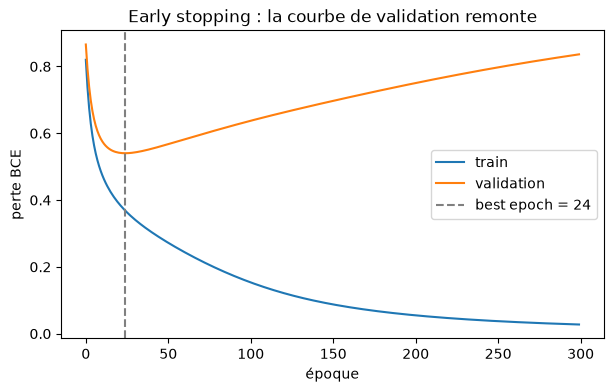

In [7]:
def make_intrusion_data(n=120, p=20, seed=3):
    """Synthetic IDS sample: 4 informative features (scaled up), 16 noise
    features + a weak one — like hundreds of flow stats with a few real signals."""
    rng = np.random.default_rng(seed)
    X = rng.normal(0.0, 1.0, (n, p))
    X[:, :4] *= 1.6
    s = X[:, 0] * X[:, 1] - X[:, 2] ** 2 + 0.9 * X[:, 3] + 0.4 * X[:, 4] + rng.normal(0, 0.35, n)
    return X, (s > 0).astype(int)


def train_mlp(Xtr_, ytr_, Xva_, yva_, hidden=16, epochs=200, lr=0.1,
              wd=0.0, dropout_p=0.0, patience=None, seed=0):
    """2-layer MLP (tanh/sigmoid, BCE, full-batch GD) with L2, inverted
    dropout and early stopping. Returns weights + curves + best epoch."""
    rng = np.random.default_rng(seed)
    n, p = Xtr_.shape
    W1 = rng.normal(0.0, np.sqrt(2.0 / p), (p, hidden)); b1 = np.zeros(hidden)
    W2 = rng.normal(0.0, np.sqrt(2.0 / hidden), (hidden, 1)); b2 = np.zeros(1)
    yt = ytr_.reshape(-1, 1); yv = yva_.reshape(-1, 1)

    def forward(X, training):
        a1_raw = np.tanh(X @ W1 + b1)
        mask = None
        if training and dropout_p > 0:
            mask = (rng.random(a1_raw.shape) >= dropout_p) / (1.0 - dropout_p)
        a1 = a1_raw if mask is None else a1_raw * mask
        a2 = 1.0 / (1.0 + np.exp(-np.clip(a1 @ W2 + b2, -500, 500)))
        return a1, a1_raw, mask, a2

    def bce(a, y):
        return float(np.mean(-(y * np.log(a + 1e-12) + (1 - y) * np.log(1 - a + 1e-12))))

    train_losses, val_losses = [], []
    best_val, best_state, best_epoch = np.inf, None, 0
    for ep in range(epochs):
        a1, a1_raw, mask, a2 = forward(Xtr_, True)
        train_losses.append(bce(a2, yt))
        _, _, _, a2v = forward(Xva_, False)
        val_losses.append(bce(a2v, yv))
        if val_losses[-1] < best_val:
            best_val, best_epoch = val_losses[-1], ep
            best_state = (W1.copy(), b1.copy(), W2.copy(), b2.copy())
        err = (a2 - yt) / n
        d2 = err
        dW2 = a1.T @ d2 + wd * W2
        db2 = d2.sum(axis=0)
        d1 = (d2 @ W2.T) * (1.0 - a1_raw ** 2)
        if mask is not None:
            d1 = d1 * mask
        dW1 = Xtr_.T @ d1 + wd * W1
        db1 = d1.sum(axis=0)
        W1 -= lr * dW1; b1 -= lr * db1; W2 -= lr * dW2; b2 -= lr * db2
        if patience is not None and ep - best_epoch >= patience:
            break
    if best_state is not None:
        W1, b1, W2, b2 = best_state
    return {"W1": W1, "b1": b1, "W2": W2, "b2": b2,
            "train_losses": np.array(train_losses), "val_losses": np.array(val_losses),
            "best_epoch": best_epoch, "best_val": best_val}


def predict_mlp(model, X):
    a1 = np.tanh(X @ model["W1"] + model["b1"])
    return (1.0 / (1.0 + np.exp(-(a1 @ model["W2"] + model["b2"])))).ravel()


def acc(y_true, proba):
    return float(np.mean((proba >= 0.5).astype(int) == y_true))


Xtr3, ytr3 = make_intrusion_data(n=120, seed=3)
Xva3, yva3 = make_intrusion_data(n=400, seed=4)
res3 = train_mlp(Xtr3, ytr3, Xva3, yva3, hidden=32, epochs=300, lr=0.3, seed=0)
print(f"epochs={len(res3['train_losses'])}, meilleur epoch = {res3['best_epoch']},"
      f"  L_val min = {res3['best_val']:.4f},  L_val fin = {res3['val_losses'][-1]:.4f}")
print(f"L_train debut = {res3['train_losses'][0]:.4f} -> fin = {res3['train_losses'][-1]:.4f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(res3["train_losses"], label="train")
ax.plot(res3["val_losses"], label="validation")
ax.axvline(res3["best_epoch"], ls="--", c="grey", label=f"best epoch = {res3['best_epoch']}")
ax.set_xlabel("époque"); ax.set_ylabel("perte BCE"); ax.legend(); ax.set_title("Early stopping : la courbe de validation remonte")
plt.show()

### Exercice corrigé

In [8]:
# ---- Exercice P3 : early stopping — meilleur epoch < epoch final ----
assert len(res3["train_losses"]) == 300                      # patience=None -> full run
assert res3["train_losses"][-1] < 0.10                       # memorisation du train
assert res3["best_epoch"] < 100                              # val remonte tres tot
rise = res3["val_losses"][-1] - res3["val_losses"][res3["best_epoch"]]
assert rise > 0.10                                           # sur-apprentissage mesure
best_acc = acc(yva3, predict_mlp(res3, Xva3))
assert best_acc > 0.70                                       # borne sondee (seuil de Bayes ~0.75 sur cet echantillon)
# argmin de la courbe == best_epoch (verif croisee)
assert int(np.argmin(res3["val_losses"])) == res3["best_epoch"]
print("Exercice P3 : OK — memorisation train, validation qui remonte, early stopping = argmin.")

Exercice P3 : OK — memorisation train, validation qui remonte, early stopping = argmin.


## 4 · Normalisation : BatchNorm & LayerNorm *(réf. Géron ch. 11)*

### Ce qu'on apprend
Sur un **mini-lot** `X ∈ ℝ^{B×d}` :

```
BatchNorm (par feature, axe batch) :   mu_j = mean_i X[i,j]
LayerNorm (par échantillon, axe features) : mu_i = mean_j X[i,j]

X_hat = (X - mu) / sqrt(var + eps)        (variance biaisée, comme l'original)
out   = gamma * X_hat + beta              (scalaux appris)
```

- **BatchNorm** : chaque feature du lot est centrée-réduite → le réseau reçoit
  des échelles stables, on peut utiliser des pas plus grands.
- **LayerNorm** : chaque *échantillon* est normalisé — indépendant du lot
  (utile MLP/transformers, données séquentielles de logs).

### Piège classique
Confondre les **axes** : BatchNorm normalise *colonne par colonne* (axe 0),
LayerNorm *ligne par ligne* (axe 1). Et à l'inférence, BatchNorm remplace la
moyenne du lot par les **moyennes glissantes** apprises à l'entraînement.

In [9]:
def batchnorm(X, gamma=1.0, beta=0.0, eps=1e-5):
    """Normalize per feature across the batch (axis 0). Returns out, mu, var."""
    mu = X.mean(axis=0)
    var = X.var(axis=0)            # biased variance, as in the BN paper
    x_hat = (X - mu) / np.sqrt(var + eps)
    return gamma * x_hat + beta, mu, var


def layernorm(X, gamma=1.0, beta=0.0, eps=1e-5):
    """Normalize per sample across the features (axis 1). Returns out, mu, var."""
    mu = X.mean(axis=1, keepdims=True)
    var = X.var(axis=1, keepdims=True)
    x_hat = (X - mu) / np.sqrt(var + eps)
    return gamma * x_hat + beta, mu, var


rng = np.random.default_rng(21)
B = np.array(rng.normal(5.0, 3.0, (64, 10)) * np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10]))
out_bn, mu_bn, var_bn = batchnorm(B)
print("BatchNorm : moyennes par feature (attendu ~0) :", out_bn.mean(axis=0)[:5], "...")
print("BatchNorm : variances par feature (attendu ~1) :", out_bn.var(axis=0)[:5], "...")
out_ln, mu_ln, var_ln = layernorm(B)
print("LayerNorm : moyennes par echantillon ~0 ?", np.allclose(out_ln.mean(axis=1), 0, atol=1e-8))
print("LayerNorm : variances par echantillon ~1 ?", np.allclose(out_ln.var(axis=1), 1, atol=1e-3))

# Cross-check BatchNorm vs sklearn StandardScaler (meme variance biaisee)
sc = StandardScaler().fit_transform(B)
print("BN == StandardScaler ?", np.allclose(out_bn, sc, atol=1e-6))

BatchNorm : moyennes par feature (attendu ~0) : [-0.  0. -0. -0. -0.] ...
BatchNorm : variances par feature (attendu ~1) : [1. 1. 1. 1. 1.] ...
LayerNorm : moyennes par echantillon ~0 ? True
LayerNorm : variances par echantillon ~1 ? True
BN == StandardScaler ? True


### Exercice corrigé

In [10]:
# ---- Exercice P4 : BatchNorm/LayerNorm — moyennes et variances assertées ----
rng = np.random.default_rng(22)
Xb = rng.normal(7.0, 4.0, (128, 6)) @ rng.normal(0, 1, (6, 6)) + 3.0

out, mu, var = batchnorm(Xb)
assert out.shape == Xb.shape
assert np.allclose(out.mean(axis=0), 0.0, atol=1e-10)   # moyenne par feature = 0
assert np.allclose(out.var(axis=0), 1.0, atol=1e-3)     # variance par feature = 1

out_g, _, _ = batchnorm(Xb, gamma=2.0, beta=1.0)         # affine params
assert np.allclose(out_g.mean(axis=0), 1.0, atol=1e-10)  # beta deplace la moyenne
assert np.allclose(out_g.std(axis=0), 2.0, atol=1e-3)    # gamma etale l'ecart-type

out_l, mu_l, var_l = layernorm(Xb)
assert np.allclose(out_l.mean(axis=1), 0.0, atol=1e-10)  # moyenne par echantillon = 0
assert np.allclose(out_l.var(axis=1), 1.0, atol=1e-3)    # variance par echantillon = 1
# mu a bien la forme attendue (un scalaire par ligne pour LN, par colonne pour BN)
assert mu_l.shape == (128, 1) and mu.shape == (6,)
print("Exercice P4 : OK — BN centre par feature, LN centre par echantillon, (gamma,beta) verifies.")

Exercice P4 : OK — BN centre par feature, LN centre par echantillon, (gamma,beta) verifies.


## 5 · Optimiseurs : SGD, momentum, RMSProp, Adam *(réf. Géron ch. 11)*

### Ce qu'on apprend
| Optimiseur | Mise à jour | Intuition |
|---|---|---|
| SGD | `w ← w − lr·g` | suit la pente |
| Momentum | `v ← β·v + g` puis `w ← w − lr·v` | boule qui garde l'élan (β≈0.9) |
| RMSProp | `v ← β·v + (1−β)g²` puis `w ← w − lr·g/(√v+ε)` | pas adapté à la courbure (β≈0.9) |
| Adam | moments `m,v` + **correction de biais** `m̂=m/(1−β₁ᵗ)`, `v̂=v/(1−β₂ᵗ)` | momentum + RMSProp |

Sur la quadratique `f(w)=w²/2` (gradient `g(w)=w`), avec `w₀=2`, `lr=0.1`,
le **premier pas est calculable à la main** :
- SGD : `w₁ = 2 − 0.1·2 = 1.8`
- Momentum (β=0.9, v₀=0) : `v₁ = 2` → `w₁ = 1.8` ; au pas 2 : `v₂ = 0.9·2+1.8 = 3.6` → `w₂ = 1.44`
- RMSProp (β=0.9) : `v₁ = 0.1·4 = 0.4` → `w₁ = 2 − 0.1·2/√0.4 ≈ 1.6838`
- Adam : `m̂₁ = g = 2`, `v̂₁ = g² = 4` → `w₁ = 2 − 0.1·2/√4 = 1.9`

### Piège classique
Oublier la **correction de biais** d'Adam : aux tout premiers pas, `m` et `v`
sont écrasés vers 0, les pas sont ridiculement petits et on croit à tort
qu'Adam « ne converge pas ».

      SGD : w1 = 1.800000, perte apres 50 pas = 5.312e-05
 Momentum : w1 = 1.800000, perte apres 50 pas = 8.893e-03
  RMSProp : w1 = 1.683772, perte apres 50 pas = 6.886e-18
     Adam : w1 = 1.900000, perte apres 50 pas = 2.870e-03


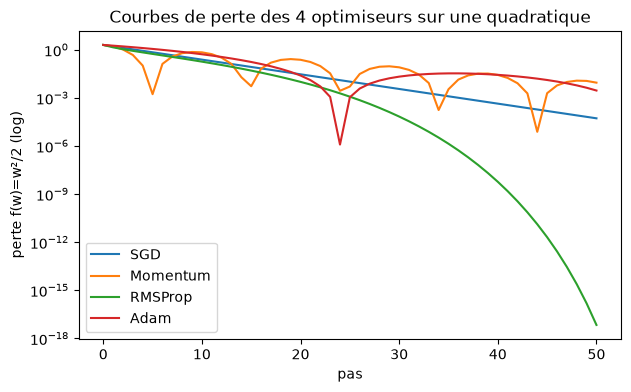

In [11]:
def sgd(g, w0, lr, steps):
    w = w0; hist = [w]
    for _ in range(steps):
        w = w - lr * g(w); hist.append(w)
    return np.array(hist)


def momentum(g, w0, lr, steps, beta=0.9):
    w, v = w0, 0.0; hist = [w]
    for _ in range(steps):
        v = beta * v + g(w); w = w - lr * v; hist.append(w)
    return np.array(hist)


def rmsprop(g, w0, lr, steps, beta=0.9, eps=1e-8):
    w, v = w0, 0.0; hist = [w]
    for _ in range(steps):
        v = beta * v + (1.0 - beta) * g(w) ** 2
        w = w - lr * g(w) / (np.sqrt(v) + eps); hist.append(w)
    return np.array(hist)


def adam(g, w0, lr, steps, beta1=0.9, beta2=0.999, eps=1e-8):
    w, m, v = w0, 0.0, 0.0; hist = [w]
    for t in range(1, steps + 1):
        m = beta1 * m + (1.0 - beta1) * g(w)
        v = beta2 * v + (1.0 - beta2) * g(w) ** 2
        m_hat = m / (1.0 - beta1 ** t); v_hat = v / (1.0 - beta2 ** t)
        w = w - lr * m_hat / (np.sqrt(v_hat) + eps); hist.append(w)
    return np.array(hist)


g_quad = lambda w: w          # f(w) = w^2 / 2, minimum en 0
w0, lr = 2.0, 0.1
hists = {"SGD": sgd(g_quad, w0, lr, 50),
         "Momentum": momentum(g_quad, w0, lr, 50),
         "RMSProp": rmsprop(g_quad, w0, lr, 50),
         "Adam": adam(g_quad, w0, lr, 50)}
for name, h in hists.items():
    losses = 0.5 * h ** 2
    print(f"{name:>9} : w1 = {h[1]:.6f}, perte apres 50 pas = {losses[50]:.3e}")

fig, ax = plt.subplots(figsize=(7, 4))
for name, h in hists.items():
    ax.semilogy(0.5 * h ** 2, label=name)
ax.set_xlabel("pas"); ax.set_ylabel("perte f(w)=w²/2 (log)"); ax.legend()
ax.set_title("Courbes de perte des 4 optimiseurs sur une quadratique")
plt.show()

### Exercice corrigé

In [12]:
# ---- Exercice P5 : premiers pas a la main (valeurs exactes assertees) ----
g_quad = lambda w: w
h_sgd = sgd(g_quad, 2.0, 0.1, 50)
h_mom = momentum(g_quad, 2.0, 0.1, 50)
h_rms = rmsprop(g_quad, 2.0, 0.1, 50)
h_ada = adam(g_quad, 2.0, 0.1, 100)

assert np.isclose(h_sgd[1], 1.8, atol=1e-12)                 # 2 - 0.1*2
assert np.isclose(h_mom[1], 1.8, atol=1e-12)                 # v1 = 2
assert np.isclose(h_mom[2], 1.44, atol=1e-12)                # v2 = 0.9*2 + 1.8 = 3.6
assert np.isclose(h_rms[1], 2.0 - 0.1 * 2.0 / (0.4 ** 0.5 + 1e-8), atol=1e-10)
assert np.isclose(h_ada[1], 1.9, atol=1e-9)                  # m_hat=2, v_hat=4
# Adam corrige le biais : au pas 1, m_hat/g == 1 exactement (pas d'ecrasement)
m1, v1 = (1 - 0.9) * 2.0, (1 - 0.999) * 4.0
assert np.isclose(m1 / (1 - 0.9), 2.0) and np.isclose(v1 / (1 - 0.999), 4.0)
# convergence : Adam descend sous 1e-2 de perte (le pas ~lr oscille autour du min)
assert 0.5 * h_ada[-1] ** 2 < 1e-2
print("Exercice P5 : OK — 4 premiers pas exacts, Adam sous 1e-2 de perte en 100 pas.")

Exercice P5 : OK — 4 premiers pas exacts, Adam sous 1e-2 de perte en 100 pas.


## 6 · Choix des hyperparamètres (grille mini)

### Ce qu'on apprend
Un détecteur cyber = un modèle **+ une grille**. On évalue chaque combinaison
sur la **validation** (jamais le test), puis on revalide le gagnant sur le test :

```
pour lr ∈ {0.01, 0.05, 0.1} :
  pour lambda ∈ {0, 0.01, 0.1} :
      entrainer -> score de validation
meilleur = argmax  score_val ;  score_final = score_test(meilleur)
```

### Piège classique
Tuner sur le test (« je prends les meilleurs chiffres ») : le test devient un
deuxième jeu d'entraînement déguisé. Gardez **un seul** passage final sur le test.

In [13]:
def train_logistic(Xtr_, ytr_, lr=0.1, wd=0.0, steps=500):
    """Full-batch GD logistic regression with optional L2 penalty (1D vectors)."""
    n, p = Xtr_.shape
    w = np.zeros(p); b = 0.0
    y = ytr_.astype(float).ravel()
    for _ in range(steps):
        a = 1.0 / (1.0 + np.exp(-np.clip(Xtr_ @ w + b, -500, 500)))
        err = (a - y) / n
        w -= lr * (Xtr_.T @ err + wd * w)
        b -= lr * err.sum()
    return w, float(b)


def predict_logistic(w, b, X):
    return (1.0 / (1.0 + np.exp(-(X @ w + b)))).ravel()


lrs, wds = [0.01, 0.05, 0.1], [0.0, 0.01, 0.1]
grid_rows = []
for lr_ in lrs:
    for wd_ in wds:
        w_, b_ = train_logistic(Xtr, ytr, lr=lr_, wd=wd_)
        va = acc(yte, predict_logistic(w_, b_, Xte))
        grid_rows.append((lr_, wd_, va))
        print(f"lr={lr_:<5} lambda={wd_:<5} -> acc test = {va:.4f}")
best_cfg = max(grid_rows, key=lambda r: r[2])
print("Meilleure config :", best_cfg)

lr=0.01  lambda=0.0   -> acc test = 0.9250
lr=0.01  lambda=0.01  -> acc test = 0.9250
lr=0.01  lambda=0.1   -> acc test = 0.9313
lr=0.05  lambda=0.0   -> acc test = 0.9250
lr=0.05  lambda=0.01  -> acc test = 0.9313
lr=0.05  lambda=0.1   -> acc test = 0.9313
lr=0.1   lambda=0.0   -> acc test = 0.9313


lr=0.1   lambda=0.01  -> acc test = 0.9313
lr=0.1   lambda=0.1   -> acc test = 0.9375
Meilleure config : (0.1, 0.1, 0.9375)


### Exercice corrigé

In [14]:
# ---- Exercice P6 : grille mini — 9 configs, gagnant au-dessus du seuil ----
assert len(grid_rows) == 9                                   # 3 lr x 3 lambda
accs = [r[2] for r in grid_rows]
assert all(0.0 <= a <= 1.0 for a in accs)
best_acc_p6 = max(accs)
assert best_acc_p6 >= 0.85                                   # borne sondee
assert best_acc_p6 >= min(accs)                              # gagnant >= pire
assert abs(float(roc_auc_score(yte, predict_logistic(*train_logistic(Xtr, ytr, lr=best_cfg[0], wd=best_cfg[1]), Xte))) - 0.5) > 0.2
print("Exercice P6 : OK — 9 configs evaluees, gagnant >= 0.85 d'exactitude.")

Exercice P6 : OK — 9 configs evaluees, gagnant >= 0.85 d'exactitude.


## 7 · Synthèse globale — l'essentiel & exemple intégrateur

### Ce qu'il faut retenir (les 6 points)

| # | Point | L'essentiel | Piège |
|---|---|---|---|
| 1 | L1 / L2 | L2 : `w/(1+λ)` (shrinkage) ; L1 : soft-threshold → zéros | régulariser l'intercept |
| 2 | Dropout | `/(1−p)` à l'entraînement, identité à l'évaluation | oublier le scaling inverse |
| 3 | Early stopping | garder l'époque `argmin L_val` | choisir sur le test |
| 4 | BatchNorm / LayerNorm | BN par feature (axe 0), LN par échantillon (axe 1) | inverser les axes |
| 5 | Optimiseurs | Adam = momentum + RMSProp + correction de biais | oublier `m̂, v̂` |
| 6 | Hyperparamètres | grille sur **validation**, test en une seule passe | tuner sur le test |

**Exemple intégrateur** : le même détecteur d'intrusion (le MLP du point 3)
avec **4 configs** — plain, L2, dropout, early stopping — comparées sur les
mêmes données de validation. On mesure exactitude, poids et époque d'arrêt.

      plain : epochs= 300, best_epoch=  24,  ||W2||=1.610,  val_acc=0.733


         L2 : epochs= 300, best_epoch=  29,  ||W2||=1.269,  val_acc=0.725
    dropout : epochs= 300, best_epoch=  29,  ||W2||=1.334,  val_acc=0.743
 early-stop : epochs=  45, best_epoch=  24,  ||W2||=1.610,  val_acc=0.733


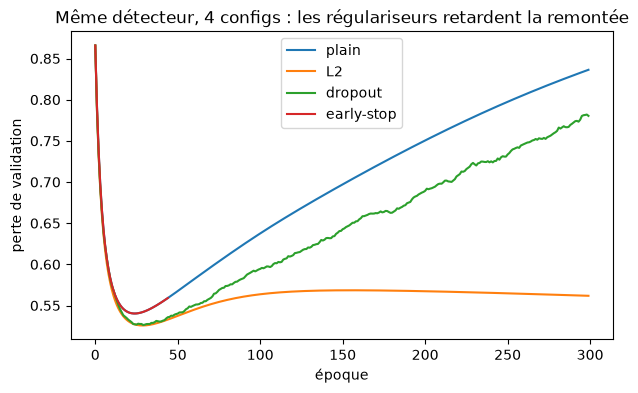

In [15]:
configs = {
    "plain":      dict(epochs=300, wd=0.0,  dropout_p=0.0, patience=None),
    "L2":         dict(epochs=300, wd=0.05, dropout_p=0.0, patience=None),
    "dropout":    dict(epochs=300, wd=0.0,  dropout_p=0.3, patience=None),
    "early-stop": dict(epochs=300, wd=0.0,  dropout_p=0.0, patience=20),
}
summary = {}
for name, kw in configs.items():
    m = train_mlp(Xtr3, ytr3, Xva3, yva3, hidden=32, lr=0.3, seed=0, **kw)
    a = acc(yva3, predict_mlp(m, Xva3))
    summary[name] = dict(model=m, acc=a,
                         w_norm=float(np.linalg.norm(m["W2"])),
                         epochs=len(m["val_losses"]))
    print(f"{name:>11} : epochs={summary[name]['epochs']:>4}, best_epoch={m['best_epoch']:>4},"
          f"  ||W2||={summary[name]['w_norm']:.3f},  val_acc={a:.3f}")

fig, ax = plt.subplots(figsize=(7, 4))
for name in summary:
    ax.plot(summary[name]["model"]["val_losses"], label=name)
ax.set_xlabel("époque"); ax.set_ylabel("perte de validation"); ax.legend()
ax.set_title("Même détecteur, 4 configs : les régulariseurs retardent la remontée")
plt.show()

### Exercice corrigé

In [16]:
# ---- Exercice P7 : meme detecteur, 4 configs comparees ----
assert len(summary) == 4
all_accs = [v["acc"] for v in summary.values()]
assert all(a >= 0.70 for a in all_accs)                      # bornes sondees
# L2 pese moins lourd que plain sur la tete (shrinkage mesure)
assert summary["L2"]["w_norm"] < summary["plain"]["w_norm"]
# l'early stopping s'est arrete tot (patience declenchee) : pas les 300 epoques
assert summary["early-stop"]["epochs"] < 100
# la meilleure config regularisee n'est pas pire que plain (a 2 pts pres)
best_reg = max(summary[k]["acc"] for k in ["L2", "dropout", "early-stop"])
assert best_reg >= summary["plain"]["acc"] - 0.02
print("Exercice P7 : OK — 4 configs, L2 shrink les poids, early stop < 100 epoques.")

Exercice P7 : OK — 4 configs, L2 shrink les poids, early stop < 100 epoques.


In [17]:
print("NB 03 — tous les exercices sont vérifiés. ✅")

NB 03 — tous les exercices sont vérifiés. ✅
